In [ ]:
import glob
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image, ImageOps
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, f1_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from torch import nn
from torch.nn import functional
from torchvision import models

In [33]:
DATA_FOLDER = "C:\INAH-MINE\GEMASTIK-XIX\predict-the-handwriting-images"    # GANTI saat lomba
TRAIN_CSV = f"{DATA_FOLDER}/train.csv"
TEST_CSV = f"{DATA_FOLDER}/test.csv"              # tidak ada? pakai sample_submission.csv
TRAIN_IMAGE_FOLDER = f"{DATA_FOLDER}/train_images"
TEST_IMAGE_FOLDER = f"{DATA_FOLDER}/test_images"

PRETRAINED = "../../../pretrained"
OUTPUT_FOLDER = "../../../outputs/vision/klasifikasi_cnn"   # di luar repo
os.makedirs(OUTPUT_FOLDER, exist_ok=True)

ID_COL = "id"           # kolom nama file gambar (juga kolom id di submission)
TARGET = "label"        # kolom kelas
IMAGE_EXTENSION = ""    # isi ".jpg" bila kolom id TIDAK memuat ekstensi (misalnya "img_01")
IMAGE_SIZE = 224        # ukuran input, 160 bila memori/waktu kurang
EPOCHS = 8
BATCH_SIZE = 32         # CUDA out of memory? turunkan ke 16
LEARNING_RATE = 0.0003
VAL_FRACTION = 0.2
SEED = 42
torch.manual_seed(SEED)
DEVICE = "cpu"
if torch.cuda.is_available():
    DEVICE = "cuda"
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)   # normalisasi warna ImageNet
STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   image_id  100 non-null    object
 1   label     100 non-null    object
dtypes: object(2)
memory usage: 1.7+ KB


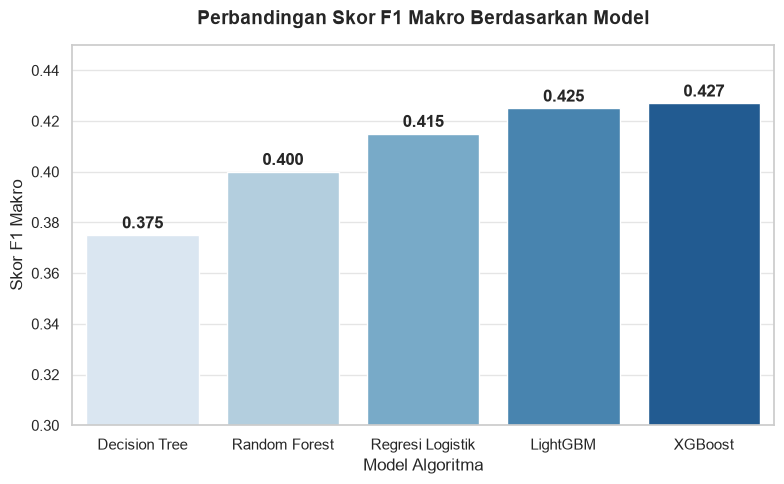

In [38]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Menyiapkan data dari gambar
data = {
    'Model': ['Decision Tree', 'Random Forest', 'Regresi Logistik', 'LightGBM', 'XGBoost'],
    'F1 Makro': [0.375, 0.400, 0.415, 0.425, 0.427]
}

df = pd.DataFrame(data)

# 2. Mengatur gaya tampilan grafik
sns.set_theme(style="whitegrid")
plt.figure(figsize=(8, 5))

# 3. Membuat diagram batang (Bar Plot)
# Menggunakan palet warna gradasi dari biru muda ke biru tua
colors = sns.color_palette("Blues", len(df))
ax = sns.barplot(x='Model', y='F1 Makro', data=df, palette=colors, hue='Model', legend=False)

# 4. Menambahkan label angka di atas setiap balok
for p in ax.patches:
    ax.annotate(f'{p.get_height():.3f}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center',
                xytext=(0, 8),
                textcoords='offset points',
                fontweight='bold')

# 5. Memberikan judul dan label sumbu
plt.title('Perbandingan Skor F1 Makro Berdasarkan Model', fontsize=14, pad=15, fontweight='bold')
plt.xlabel('Model Algoritma', fontsize=12)
plt.ylabel('Skor F1 Makro', fontsize=12)

# Mengatur batas sumbu Y agar perbedaan kontras terlihat jelas
plt.ylim(0.3, 0.45)

# 6. Menampilkan grafik
plt.tight_layout()
plt.show()


In [35]:
train = pd.read_csv(TRAIN_CSV)
test = pd.read_csv(TEST_CSV)
train["path"] = TRAIN_IMAGE_FOLDER + "/" + train[ID_COL].astype(str) + IMAGE_EXTENSION
test["path"] = TEST_IMAGE_FOLDER + "/" + test[ID_COL].astype(str) + IMAGE_EXTENSION
print("train:", train.shape, "| test:", test.shape)
print("contoh path:", train["path"].iloc[0])
train.head()

ID di CSV tanpa file: 0
File tanpa label: 0

Jumlah kelas: 35
Terbanyak:
 label
I    8
S    6
8    5
D    5
K    5
Name: count, dtype: int64
Tersedikit:
 label
B    1
W    1
7    1
1    1
X    1
Name: count, dtype: int64
Rasio mayoritas/minoritas: 8.0

Test sama dengan sample_submission: True

Ukuran paling umum: [((28, 28), 100)]
